# Demo dự báo thống kê: baseline, ARIMA và SARIMA

Các cấu hình được chọn trên train/validation trước khi chấm test. Chạy đầy đủ mặc định; có tùy chọn xem CV đã lưu để rút thời gian quay, được ghi rõ.

Chạy từ trên xuống bằng **Restart Kernel → Run All**, hoặc Shift+Enter từng cell. Thuật toán dùng lại từ `source/`; không sửa các CSV nghiên cứu đã có. Xem `notebooks/README.md` để cấu hình đường dẫn/kernel.

## Đường dẫn và môi trường
Kiểm tra các đường dẫn trước khi chạy. Các notebook độc lập: mặc định đọc clean/preparation đã lưu; không yêu cầu chạy notebook trước để có biến trong RAM.

In [14]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p/'source/preprocessing').is_dir() and (p/'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from the repository root or notebooks directory.')
for folder in [PROJECT_ROOT, PROJECT_ROOT/'notebooks', PROJECT_ROOT/'source/preprocessing']:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from demo_support import (configure, show_paths, demo_directory, save_table, save_json,
                          show_source, show_png, environment, compare_values, read_series, series_plot)
PATHS = configure(PROJECT_ROOT)
# Nếu cần, sửa PATHS.population_raw / history_raw / population_clean / history_clean / preparation tại đây.
show_paths(PATHS)
print('Python kernel:', sys.executable)


,setting,path,exists
0,project,D:\Phân tích kinh doanh_2627\GitHub\IS403.R14....,True
1,data_root,D:\Phân tích kinh doanh_2627,True
2,population_raw,D:\Phân tích kinh doanh_2627\archive\Electric_...,True
3,history_raw,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
4,population_clean,D:\Phân tích kinh doanh_2627\archive\EV_Popula...,True
5,history_clean,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
6,preparation,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True
7,output_root,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True


Python kernel: c:\Users\ASUS\AppData\Local\Programs\Python\Python312\python.exe


In [15]:
OUT = demo_directory(PATHS, 'statistical_forecasting')
print('Output demo:', OUT)
display(environment())


Output demo: D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\notebook_demo\statistical_forecasting_20261116_040344_01d0f033


,package,version,status
0,pandas,3.0.5,Đã tìm thấy
1,numpy,2.5.3,Đã tìm thấy
2,scipy,1.18.1,Đã tìm thấy
3,matplotlib,3.11.2,Đã tìm thấy
4,statsmodels,0.15.0,Đã tìm thấy
5,scikit-learn,1.9.1,Đã tìm thấy
6,xgboost,3.4.1,Đã tìm thấy
7,ipykernel,7.3.0,Đã tìm thấy


## Dữ liệu và protocol
83 tháng, 71 train/12 test. Không cập nhật actual test vào các bước dự báo.

In [16]:
from source.forecasting.protocol import load_protocol
from source.forecasting import diagnostics
from source.forecasting.models import arima, sarima, baselines
from source.forecasting.models.statistical import forecast_distribution
from source.forecasting.backtest import run_cross_validation
from source.forecasting.metrics import calculate_metrics
from source.forecasting.run_forecast import candidates, fit_candidates, select_arima, select_sarima, forecast_frame
series = read_series(PATHS)
train = series.loc[series['split'].eq('train')].copy()
test = series.loc[series['split'].eq('test')].copy()
display(pd.DataFrame([{'train_start':train.date.min(),'train_end':train.date.max(),'n_train':len(train),
                       'test_start':test.date.min(),'test_end':test.date.max(),'n_test':len(test)}]))
display(load_protocol())


,train_start,train_end,n_train,test_start,test_end,n_test
0,2017-01-31,2022-11-30,71,2022-12-31,2023-11-30,12


{'series_file': 'statewide_monthly.csv generated by preparation',
 'columns': ['date',
  'bev',
  'phev',
  'ev_total',
  'non_ev',
  'total_vehicles',
  'ev_pct',
  'split'],
 'target': 'ev_total',
 'target_unit': 'vehicles at month end',
 'first_month': '2017-01-31',
 'last_month': '2023-11-30',
 'train_end': '2022-11-30',
 'test_start': '2022-12-31',
 'horizon': 12,
 'cv_train_months': [47, 53, 59],
 'cv_origins': ['2020-11-30', '2021-05-31', '2021-11-30'],
 'ml_features': ['r_lag_1', 'r_lag_2', 'r_lag_3', 'r_mean_3', 'r_mean_6'],
 'ml_target': 'ln(y_t) - ln(y_(t-1)); not multiplied by 100',
 'forecast_strategy': 'fixed origin; no updates with test actuals',
 'metrics': ['rmse', 'mae', 'smape', 'bias'],
 'bias_definition': 'mean(actual - pred)',
 'smape_definition': 'mean(200 * abs(actual-pred) / (abs(actual)+abs(pred))); 0 contribution when both are 0',
 'rounding': 'none before CSV export, selection or scoring',
 'prediction_interval_alpha': 0.05,
 'seed': 42}

## Chẩn đoán chỉ trên train
ADF/KPSS có H0 khác nhau; giữ dấu < hoặc > của p tại biên KPSS. ACF/PACF không tự chứng minh mùa vụ.

,test,transformation,regression,p_display,null_hypothesis,lags
0,ADF,level,c,=0.9989905,unit root,3
1,KPSS,level,c,<0.01,level stationary,5
2,ADF,level,ct,=1,unit root,3
3,KPSS,level,ct,<0.01,trend stationary,5
4,ADF,difference_1,c,=0.96751383,unit root,2
5,KPSS,difference_1,c,<0.01,level stationary,4
6,ADF,difference_2,c,=2.9976227e-23,unit root,1
7,KPSS,difference_2,c,>0.1,level stationary,14
8,ADF,difference_1_seasonal_12,c,=0.002452435,unit root,0
9,KPSS,difference_1_seasonal_12,c,=0.095126635,level stationary,4


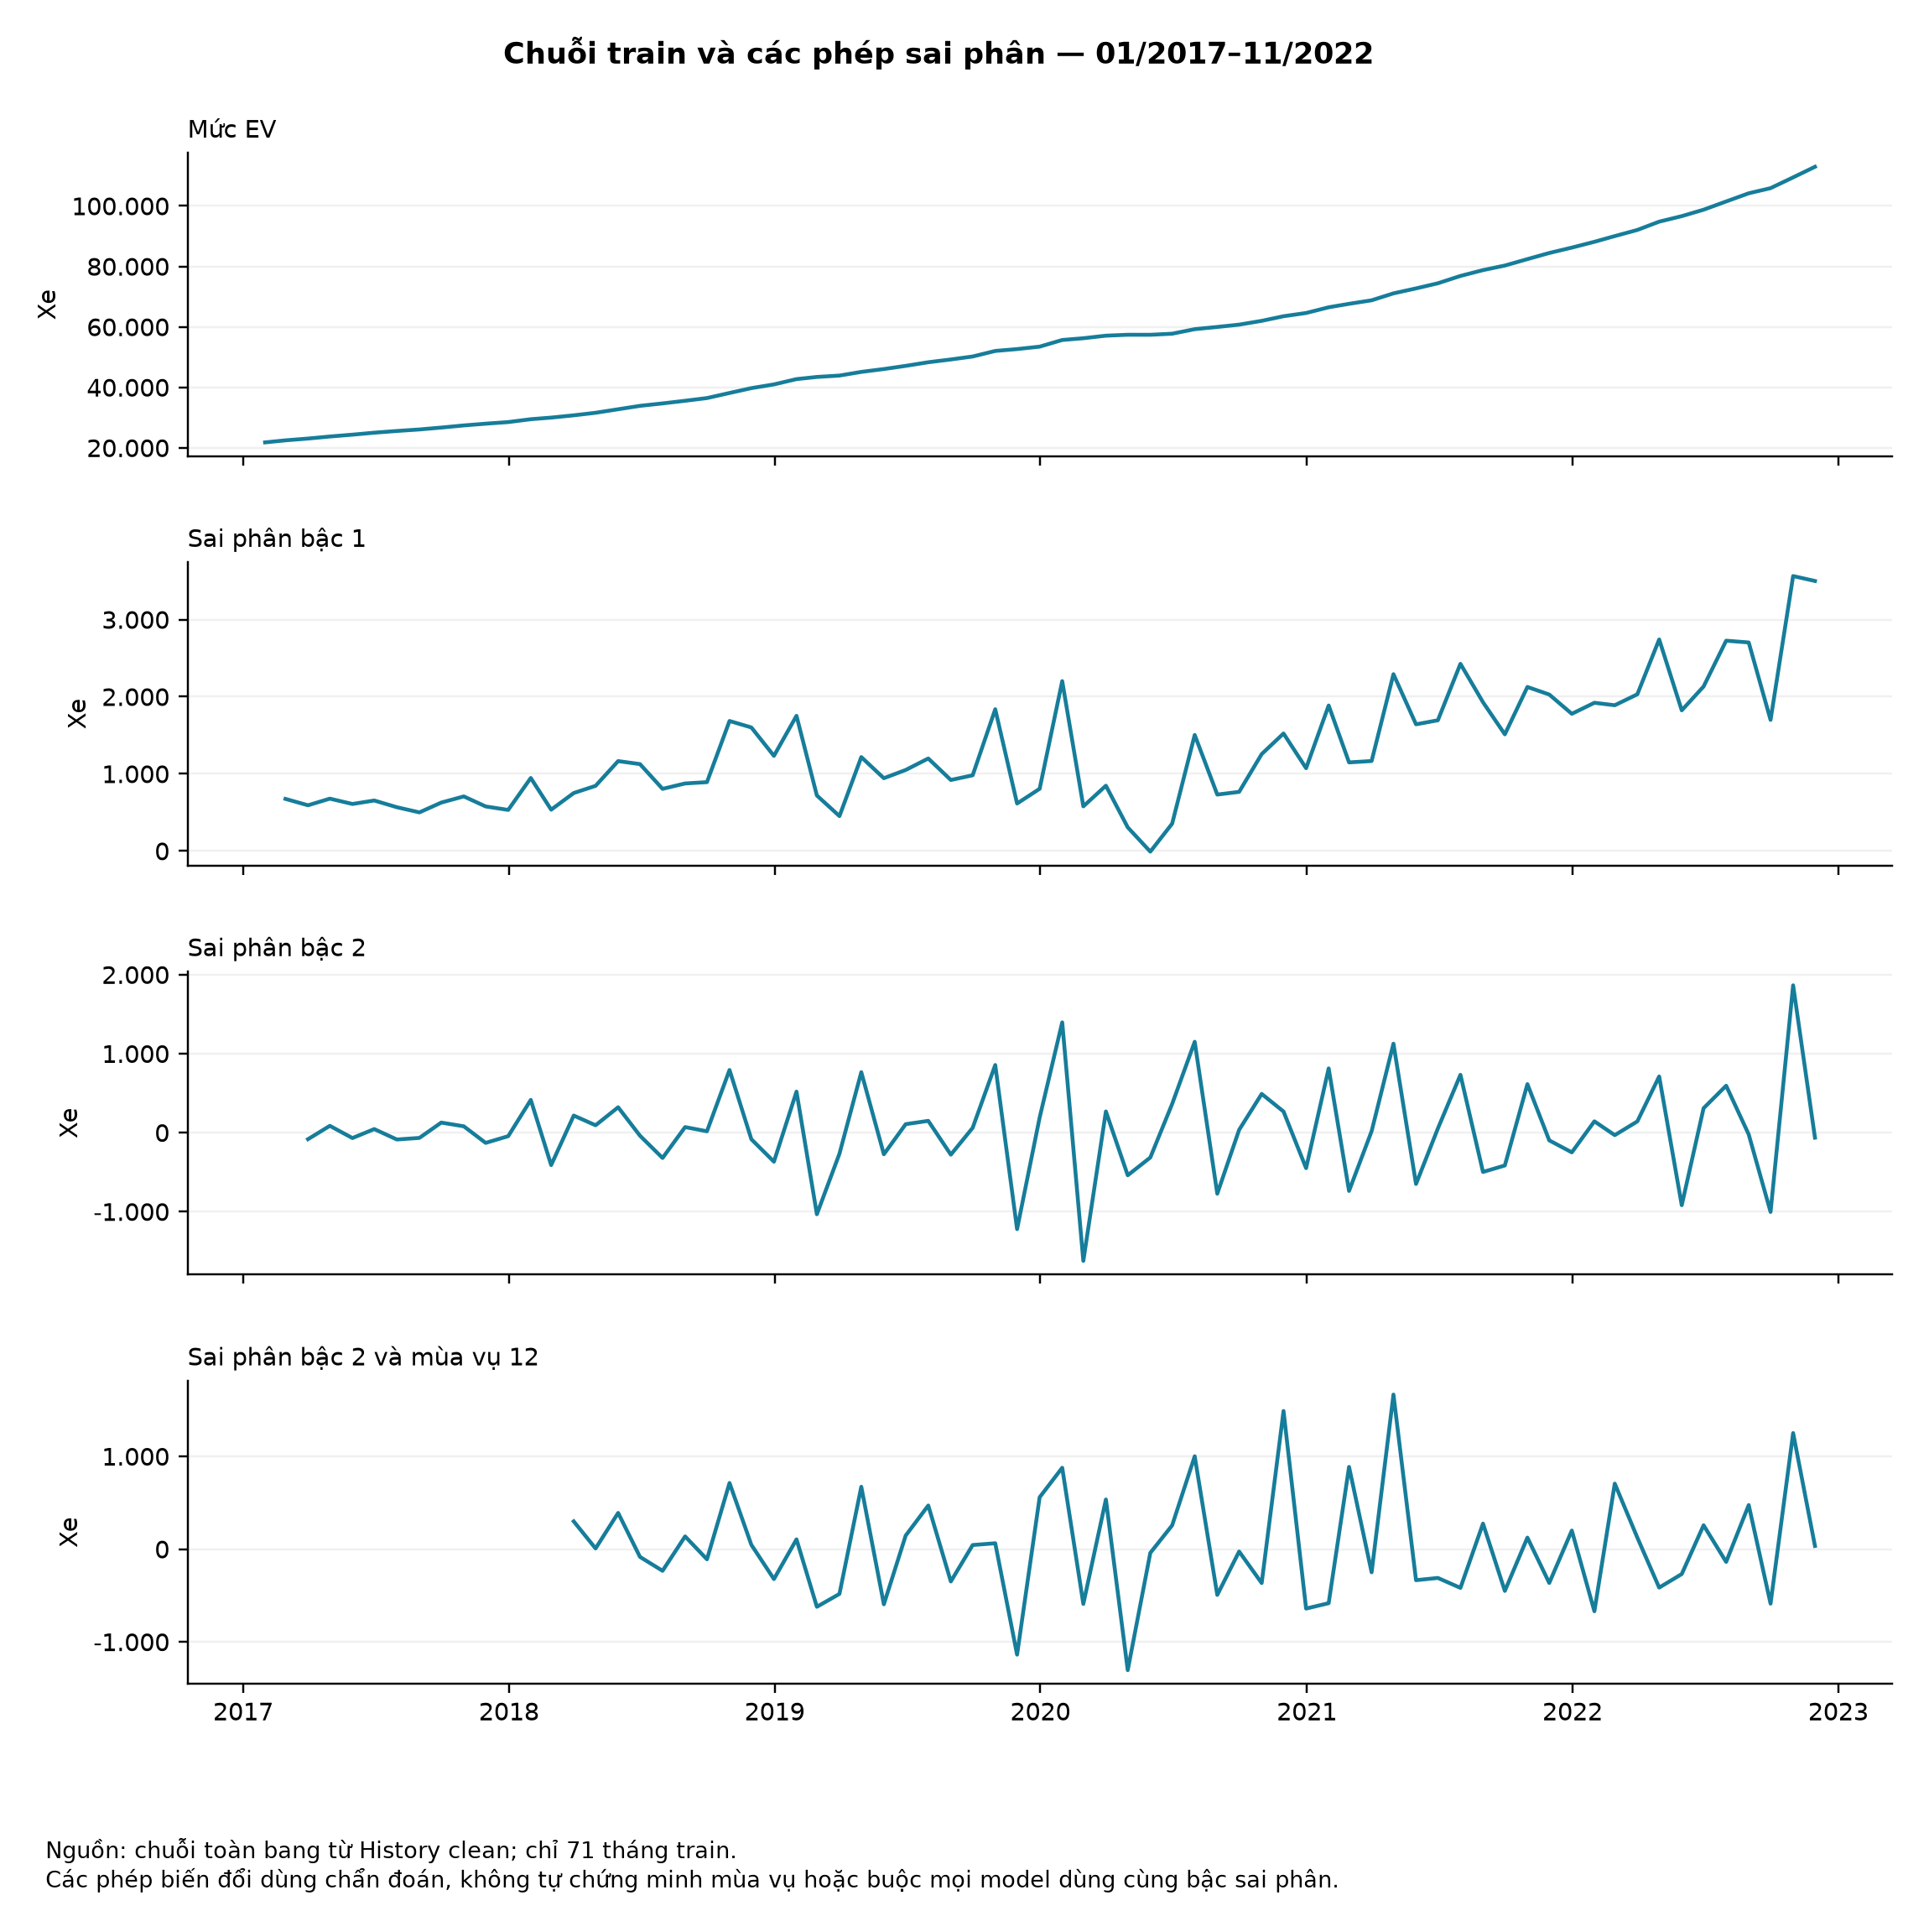

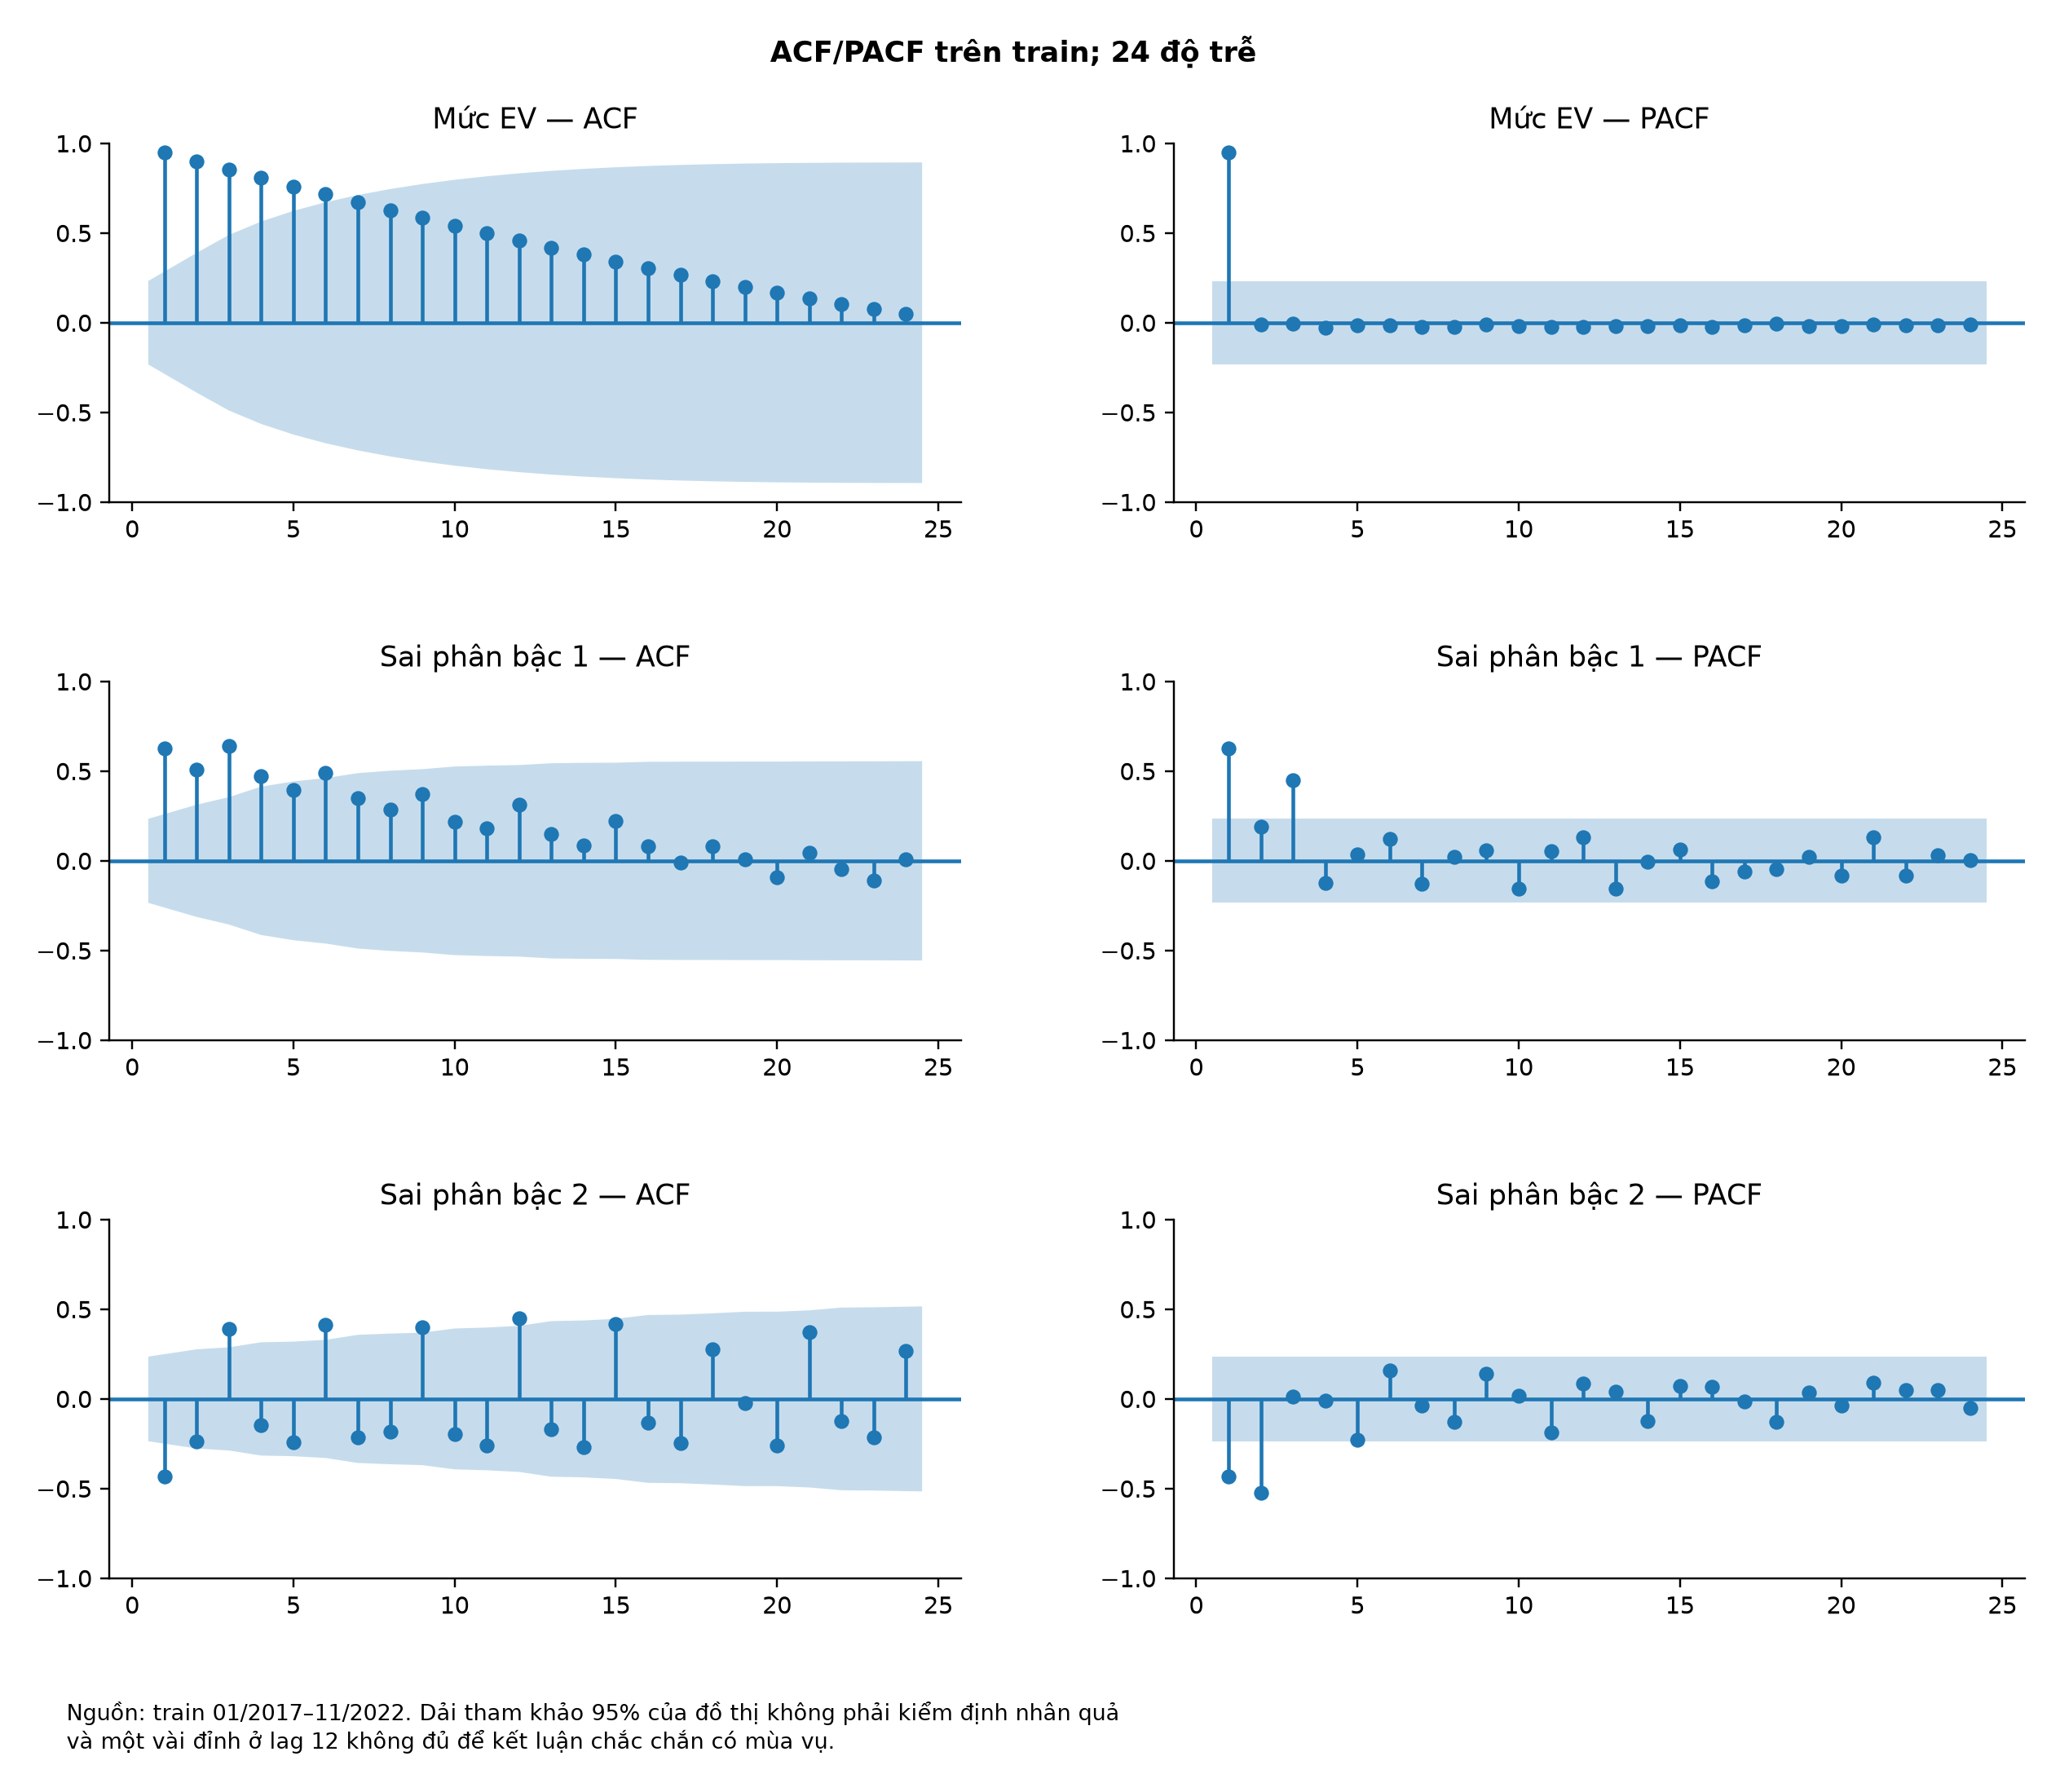

In [17]:
stationarity, correlations = diagnostics.train_diagnostics(train)
display(stationarity[['test','transformation','regression','p_display','null_hypothesis','lags']])
(OUT/'figures/train').mkdir(parents=True, exist_ok=True)
diagnostics.export_train_figures(train, OUT/'figures/train')
show_png(OUT/'figures/train/train_transformations.png')
show_png(OUT/'figures/train/train_acf_pacf.png')


## Fit sáu ARIMA và khóa lựa chọn bằng AIC
Các ứng viên cùng d=2; source kiểm tra burn và hội tụ. Chưa dự báo/chấm test tại cell này.

In [5]:
_, arima_configs = candidates('arima')
arima_artifacts, arima_scores = fit_candidates(train, arima_configs, arima.fit)
arima_id = select_arima(arima_scores)
display(arima_scores[['config_id','aic','bic','converged','status','wald_inference_caution']])
print('Locked ARIMA:', arima_id)


,config_id,aic,bic,converged,status,wald_inference_caution
0,ARIMA_120,1074.031254,1078.499467,True,ok,False
1,ARIMA_220,1063.676516,1070.378835,True,ok,False
2,ARIMA_021,1069.249293,1073.717506,True,ok,False
3,ARIMA_121,1070.052286,1076.754605,True,ok,False
4,ARIMA_221,1065.149245,1074.085671,True,ok,False
5,ARIMA_222,1052.003587,1063.174119,True,ok,True


Locked ARIMA: ARIMA_222


## SARIMA: validation nội train
True thực sự chạy 9 fold-fit. False chỉ đọc bảng validation đã lưu (phải nói rõ trong video); vẫn fit full train bên dưới. Không dùng AIC để xếp A/B/C khác bậc sai phân.

In [18]:
RUN_SARIMA_CV = True
_, sarima_configs = candidates('sarima')
if RUN_SARIMA_CV:
    cv_sarima = pd.concat([run_cross_validation(series,sarima.fit,sarima.forecast,c) for c in sarima_configs],ignore_index=True)
    print('CV mode: recomputed from training prefixes.')
else:
    cv_sarima = pd.read_csv(PROJECT_ROOT/'results/forecasting/cv_sarima.csv')
    print('CV mode: displaying previously saved validation; not recomputed in this cell.')
display(cv_sarima[['config_id','fold','origin','rmse','status']])
sarima_artifacts, full_scores = fit_candidates(train, sarima_configs, sarima.fit)
sarima_id, sarima_scores = select_sarima(cv_sarima, full_scores)
display(sarima_scores[['config_id','mean_cv_rmse','eligible_for_selection','selected']])
print('Locked SARIMA:', sarima_id)


CV mode: recomputed from training prefixes.


,config_id,fold,origin,rmse,status
0,SARIMA_A,1,2020-11-30,5531.223033,ok
1,SARIMA_A,2,2021-05-31,5512.289931,ok
2,SARIMA_A,3,2021-11-30,4100.168395,ok
3,SARIMA_B,1,2020-11-30,5565.951077,ok
4,SARIMA_B,2,2021-05-31,6205.785060,ok
5,SARIMA_B,3,2021-11-30,5729.181038,ok
6,SARIMA_C,1,2020-11-30,2988.941811,ok
7,SARIMA_C,2,2021-05-31,2413.830286,ok
8,SARIMA_C,3,2021-11-30,1624.116817,ok


,config_id,mean_cv_rmse,eligible_for_selection,selected
0,SARIMA_A,5047.893787,True,False
1,SARIMA_B,5833.639059,True,False
2,SARIMA_C,2342.296305,True,True


Locked SARIMA: SARIMA_C


## Chẩn đoán mô hình và cảnh báo
ARIMA có thể hội tụ nhưng covariance điều kiện số kém. Không bỏ cảnh báo vì điểm dự báo tốt.

In [19]:
diagnostic_rows = []
for label,artifact in [('ARIMA',arima_artifacts[arima_id]),('SARIMA',sarima_artifacts[sarima_id])]:
    display(pd.DataFrame([artifact['metadata']]))
    diag,residuals,parameters = diagnostics.fitted_diagnostics(artifact, train)
    display(diag)
    display(parameters.head())
    diagnostic_rows.append(diag)


,config_id,n_train_months,train_start,train_end,aic,bic,...,covariance_rank_definition,minimum_abs_ar_root,minimum_abs_ma_root,root_within_001_of_unit_circle,wald_inference_caution,warnings
0,ARIMA_222,71,2017-01-31,2022-11-30,1052.003587,1063.174119,...,NumPy default numerical rank of raw covariance...,1.000239,1.000361,True,True,[]


,config_id,residual_kind,burn,residual_n,model_df,lag,ljung_box_statistic,ljung_box_p_value,jarque_bera_statistic,jarque_bera_p_value,residual_mean,residual_std
0,ARIMA_222,standardized one-step forecast errors,2,69,4,12,14.536067,0.068819,3.177551,0.204175,0.080874,0.951031
1,ARIMA_222,standardized one-step forecast errors,2,69,4,24,21.054885,0.393908,3.177551,0.204175,0.080874,0.951031


,config_id,parameter,estimate,standard_error,z_value,p_value,p_display,lower_95,upper_95,covariance_rank_deficient,wald_inference_caution,covariance_condition_number
0,ARIMA_222,ar.L1,-0.977134,0.040656,-2.403419e+01,1.221561e-127,1.2215607e-127,-1.056818,-0.897450,True,True,1.972707e+26
1,ARIMA_222,ar.L2,-0.999522,0.006443,-1.551351e+02,NaN,<1e-300 (numerical underflow),-1.012150,-0.986894,True,True,1.972707e+26
2,ARIMA_222,ma.L1,0.967034,0.144075,6.712031e+00,1.919335e-11,1.9193352e-11,0.684653,1.249415,True,True,1.972707e+26
3,ARIMA_222,ma.L2,0.999278,0.187935,5.317138e+00,1.054122e-07,1.0541222e-07,0.630932,1.367625,True,True,1.972707e+26
4,ARIMA_222,sigma2,223317.359694,0.000001,2.053168e+11,NaN,<1e-300 (numerical underflow),223317.359692,223317.359696,True,True,1.972707e+26


,config_id,n_train_months,train_start,train_end,aic,bic,...,covariance_rank_definition,minimum_abs_ar_root,minimum_abs_ma_root,root_within_001_of_unit_circle,wald_inference_caution,warnings
0,SARIMA_C,71,2017-01-31,2022-11-30,879.513188,885.642341,...,NumPy default numerical rank of raw covariance...,None,1.079587,False,False,[]


,config_id,residual_kind,burn,residual_n,model_df,lag,ljung_box_statistic,ljung_box_p_value,jarque_bera_statistic,jarque_bera_p_value,residual_mean,residual_std
0,SARIMA_C,standardized one-step forecast errors,14,57,2,12,10.863348,0.368263,1.077012,0.58362,0.177719,1.054534
1,SARIMA_C,standardized one-step forecast errors,14,57,2,24,23.692599,0.363547,1.077012,0.58362,0.177719,1.054534


,config_id,parameter,estimate,standard_error,z_value,p_value,p_display,lower_95,upper_95,covariance_rank_deficient,wald_inference_caution,covariance_condition_number
0,SARIMA_C,ma.L1,-0.238513,0.073585,-3.241351,1.189646e-03,0.0011896458,-0.382736,-0.094290,False,False,3.294555e+11
1,SARIMA_C,ma.S.L12,-0.398942,0.127347,-3.132705,1.732036e-03,0.0017320356,-0.648538,-0.149345,False,False,3.294555e+11
2,SARIMA_C,sigma2,227020.191667,41309.942094,5.495534,3.895299e-08,3.8952986e-08,146054.192959,307986.190374,False,False,3.294555e+11


## Sau khi khóa cả hai lựa chọn: dự báo 12 bước
Không fit bằng test. Khoảng 95% có điều kiện theo fit, không là bảo đảm độ bao phủ dài hạn.

,model,date,actual,pred
0,Naive,2022-12-31,115665,112948.0
1,Naive,2023-01-31,119377,112948.0
2,Naive,2023-02-28,122322,112948.0
3,Naive,2023-03-31,125478,112948.0
4,Naive,2023-04-30,129728,112948.0
5,Naive,2023-05-31,133975,112948.0
6,Naive,2023-06-30,138353,112948.0
7,Naive,2023-07-31,142537,112948.0
8,Naive,2023-08-31,148730,112948.0
9,Naive,2023-09-30,152690,112948.0


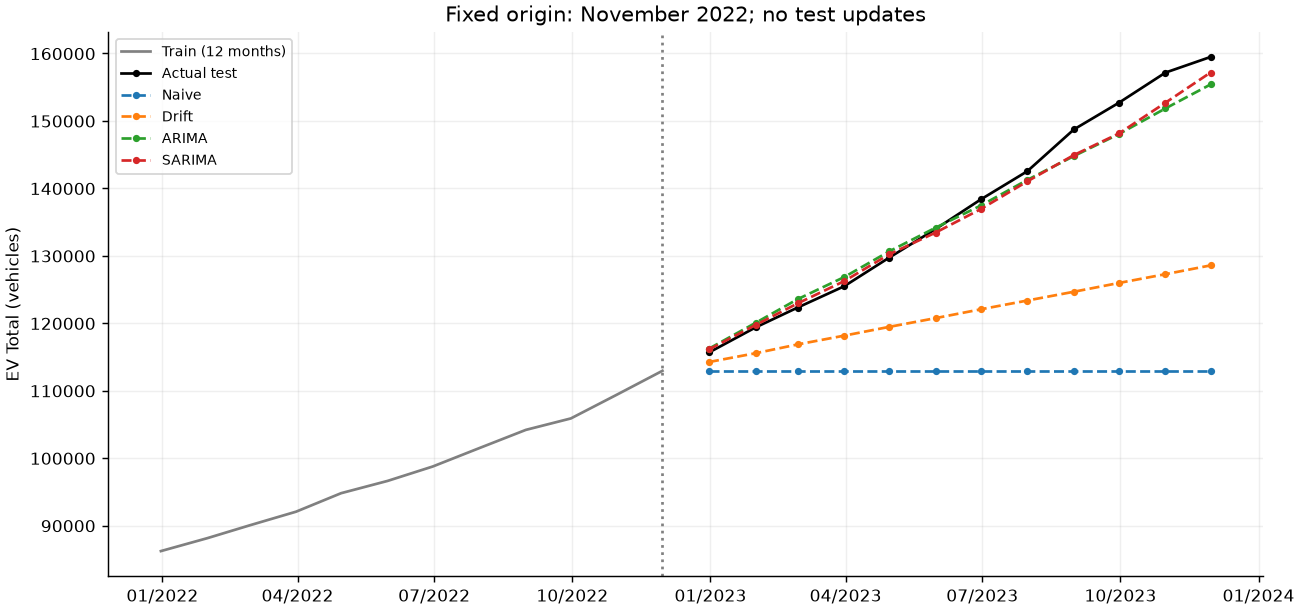

In [20]:
predictions = {name:baselines.forecast(train.ev_total,name,12) for name in ['Naive','Drift']}
forecast_tables = []
for name,pred in predictions.items(): forecast_tables.append(forecast_frame(name,name.upper(),test,pred,'baseline'))
for name,cid,artifact in [('ARIMA',arima_id,arima_artifacts[arima_id]),('SARIMA',sarima_id,sarima_artifacts[sarima_id])]:
    pred,lower,upper = forecast_distribution(artifact,12,.05)
    predictions[name] = pred
    forecast_tables.append(forecast_frame(name,cid,test,pred,'selected',lower,upper))
forecasts = pd.concat(forecast_tables,ignore_index=True)
display(forecasts[['model','date','actual','pred']].head(12))
series_plot(train,test,predictions)


## Chấm điểm, đối chiếu và lưu demo
Tính lại metric trực tiếp; không sử dụng score test để thay cấu hình đã khóa.

In [21]:
metrics = pd.DataFrame([dict(model=name,**calculate_metrics(test.ev_total,pred)) for name,pred in predictions.items()])
display(metrics)
reference = pd.read_csv(PROJECT_ROOT/'results/forecasting/statistical_test_metrics.csv')
for row in metrics.to_dict('records'):
    old = reference.loc[reference.model.eq(row['model']) & reference.evaluation_role.isin(['selected','baseline'])].iloc[0]
    compare_values(row['model']+' test metrics',[row[m] for m in ['rmse','mae','smape','bias']],old[['rmse','mae','smape','bias']].to_numpy(dtype=float))
save_table(metrics,OUT/'statistical_demo_metrics.csv')
save_table(forecasts,OUT/'statistical_demo_forecasts.csv')
save_table(arima_scores,OUT/'arima_train_scores.csv')
save_table(cv_sarima,OUT/'cv_sarima.csv')
save_table(sarima_scores,OUT/'sarima_selection.csv')
save_table(stationarity,OUT/'stationarity_tests.csv')


,model,rmse,mae,smape,bias
0,Naive,28162.950452,24176.500000,18.733318,24176.500000
1,Drift,18606.539282,15712.292857,11.655778,15712.292857
2,ARIMA,2730.715887,2094.023345,1.446599,1268.546047
3,SARIMA,2354.900778,1771.095823,1.217804,1326.434189


,check,passed,max_absolute_difference
0,Naive test metrics,True,3.637979e-12


,check,passed,max_absolute_difference
0,Drift test metrics,True,1.776357e-15


,check,passed,max_absolute_difference
0,ARIMA test metrics,True,0.0


,check,passed,max_absolute_difference
0,SARIMA test metrics,True,0.0
